# 02 — Results: fixed vs agentic vs cascade, stage by stage

Reads the tables written by `make b3-report` in `results/evaluation/`. Every number below comes
from those files; the protocol was frozen before they existed. 100 evaluation questions,
generator `qwen2.5:7b-instruct`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

R = Path("../results/evaluation")
summary = pd.read_csv(R / "summary.csv")
diagnosis = pd.read_csv(R / "diagnosis.csv")
tests = pd.read_csv(R / "paired_tests.csv")
strata = pd.read_csv(R / "strata.csv")
layers = pd.read_csv(R / "layer_economics.csv")
explore = pd.read_csv(R / "exploratory.csv")
SYSTEMS = ["oracle_context", "fixed", "agentic", "cascade"]

## 1. The main table

Brackets are 95 % bootstrap intervals (10,000 resamples of the questions).

In [2]:
def fmt(r, m):
    return f"{r[m]:.2f} [{r[m + '_lo']:.2f}, {r[m + '_hi']:.2f}]"

pd.DataFrame({
    "system": summary.system,
    "pass_all_ctx": summary.pass_all_ctx.round(2),
    "exec_accuracy": [fmt(r, "exec_accuracy") for _, r in summary.iterrows()],
    "wrong_answer": [fmt(r, "wrong_answer_rate") for _, r in summary.iterrows()],
    "refusal": summary.refusal_rate.round(2),
    "grounded": summary.grounded.round(2),
    "llm_calls": summary.llm_calls_mean.round(1),
    "tool_calls": summary.tool_calls_mean.round(1),
    "ctx_tokens_p50": summary.context_tokens_p50.round(0),
    "latency_p50_s": (summary.latency_p50_ms / 1000).round(1),
    "latency_p95_s": (summary.latency_p95_ms / 1000).round(1),
    "usd_per_1000": summary.usd_per_1000_questions.round(2),
})

,system,pass_all_ctx,exec_accuracy,wrong_answer,refusal,grounded,llm_calls,tool_calls,ctx_tokens_p50,latency_p50_s,latency_p95_s,usd_per_1000
0,oracle_context,1.00,"0.44 [0.34, 0.54]","0.34 [0.25, 0.43]",0.12,0.65,1.0,0.0,258.0,1.1,2.2,0.35
1,fixed,0.94,"0.28 [0.19, 0.37]","0.40 [0.30, 0.50]",0.05,0.45,1.0,0.0,2482.0,3.2,4.3,1.18
2,agentic,0.98,"0.18 [0.11, 0.26]","0.31 [0.22, 0.40]",0.33,0.24,6.3,4.9,2602.0,8.8,12.6,8.95
3,cascade,0.98,"0.21 [0.13, 0.29]","0.32 [0.23, 0.41]",0.21,0.44,5.1,3.2,2539.0,9.7,15.7,7.02


## 2. Accuracy against cost

Each point is a system, with its 95 % interval. Further right costs more; higher is better. Fixed
sits top-left: the cheapest, with the highest point estimate of the deployable systems (the
intervals overlap; section 4 tests the gaps).

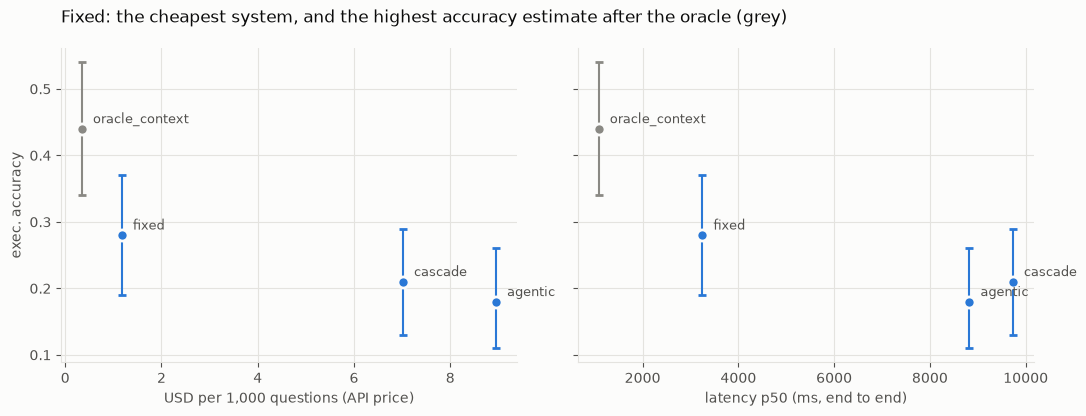

In [3]:
SERIES, ORACLE, INK, INK2, GRID, SURFACE = "#2a78d6", "#8a8984", "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True, facecolor=SURFACE)
for ax, (x, label) in zip(axes, [("usd_per_1000_questions", "USD per 1,000 questions (API price)"),
                                 ("latency_p50_ms", "latency p50 (ms, end to end)")]):
    ax.set_facecolor(SURFACE)
    for _, r in summary.iterrows():
        color = ORACLE if r.system == "oracle_context" else SERIES
        err = [[r.exec_accuracy - r.exec_accuracy_lo], [r.exec_accuracy_hi - r.exec_accuracy]]
        ax.errorbar(r[x], r.exec_accuracy, yerr=err, fmt="o", ms=8, color=color, ecolor=color,
                    elinewidth=1.5, capsize=3, mec=SURFACE, mew=2)
        ax.annotate(r.system, (r[x], r.exec_accuracy), xytext=(8, 4), textcoords="offset points",
                    color=INK2, fontsize=9)
    ax.set_xlabel(label, color=INK2)
    ax.grid(color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=INK2)
axes[0].set_ylabel("exec. accuracy", color=INK2)
fig.suptitle("Fixed: the cheapest system, and the highest accuracy estimate after the oracle (grey)",
             color=INK, x=0.06, ha="left")
fig.tight_layout()

## 3. Where failures come from: the diagnosis table

Retrieval is scored on the context, generation on the answer; the two are joined only here.
`hit_wrong` = generation failure on a complete context; `miss_wrong` = retrieval failure.

In [4]:
diagnosis.set_index("system").loc[SYSTEMS]

,hit_correct,hit_wrong,miss_correct,miss_wrong
system,,,,
oracle_context,44,56,0,0
fixed,27,67,1,5
agentic,16,82,2,0
cascade,20,78,1,1


## 4. Paired tests (exact McNemar, Holm over the six tests)

`a_only`: questions where system `a` is right and `b` wrong (for `wrong_answer`: `a` wrong and `b`
not). Only discordant questions carry evidence. Nothing is significant: every gap is "not shown".

In [5]:
tests.round(4)

,metric,a,b,rate_a,rate_b,delta,a_only,b_only,p_value,p_holm,significant
0,correct,fixed,agentic,0.28,0.18,-0.10,17,7,0.0639,0.3835,False
1,correct,fixed,cascade,0.28,0.21,-0.07,9,2,0.0654,0.3835,False
2,correct,agentic,cascade,0.18,0.21,0.03,5,8,0.5811,1.0000,False
3,wrong_answer,fixed,agentic,0.40,0.31,-0.09,20,11,0.1496,0.4488,False
4,wrong_answer,fixed,cascade,0.40,0.32,-0.08,12,4,0.0768,0.3835,False
5,wrong_answer,agentic,cascade,0.31,0.32,0.01,7,8,1.0000,1.0000,False


## 5. Strata

A level with fewer than 20 questions has no interval (protocol: descriptive only).

In [6]:
strata.pivot_table(index=["stratum", "level", "n"], columns="system", values="exec_accuracy").round(2)[SYSTEMS]

system                         oracle_context  fixed  agentic  cascade
stratum         level      n                                          
fixed_retrieval hit        94            0.45   0.29     0.17     0.21
                miss       6             0.33   0.17     0.33     0.17
gold_type       table      61            0.44   0.30     0.18     0.25
                table+text 14            0.29   0.21     0.14     0.14
                text       25            0.52   0.28     0.20     0.16
n_gold_chunks   1          80            0.45   0.30     0.16     0.24
                2+         20            0.40   0.20     0.25     0.10

## 6. Layer economics

Each layer against the system without it. Retrieval layers: Block 2, 1,147 questions,
`pass_all@10`. Agentic loop: this block, `exec_accuracy`. No cost per point without a gain.

In [7]:
layers[["layer", "compared", "metric", "gain_points", "latency_p50_ms_added",
        "llm_tokens_added", "latency_ms_per_point", "one_time_cost"]].round(2)

,layer,compared,metric,gain_points,latency_p50_ms_added,llm_tokens_added,latency_ms_per_point,one_time_cost
0,hybrid,dense -> hybrid,pass_all@10,5.23,2.89,0.00,0.55,BM25 index (CPU)
1,reranker,hybrid -> hybrid_rerank,pass_all@10,11.33,345.36,0.00,30.47,none
2,contextual_chunks,hybrid_rerank -> contextual_hybrid_rerank,pass_all@10,10.46,91.23,0.00,8.72,one LLM call per chunk (1702 calls)
3,agentic_loop,fixed -> agentic,exec_accuracy,-10.00,5575.31,25912.48,NaN,none


## 7. Exploratory: why the agent and the cascade behave as they do

Defined after the results were seen: these rows explain the outcome and never rank systems.
Both accuracies are measured on the **same** subset of questions.

In [8]:
explore.round(2)

,group,level,n,fixed_exec_accuracy,agentic_exec_accuracy
0,agent_stop,done,71,0.24,0.25
1,agent_stop,tool_budget,29,0.38,0.00
2,fixed_answer,grounded,45,0.31,0.24
3,fixed_answer,ungrounded,50,0.28,0.14
4,cascade,kept_fixed,35,0.31,0.23
5,cascade,escalated,65,0.26,0.15
6,escalation_signal,refusal,5,0.00,0.00
7,escalation_signal,ungrounded,50,0.28,0.14
8,escalation_signal,low_score,20,0.25,0.20


Reading guide:

- `agent_stop / tool_budget`: questions where the agent ran out of tool calls score 0 by the
  frozen rule, while fixed got some of them right.
- `fixed_answer`: grounded and ungrounded answers are right about equally often, so the grounding
  check is not a confidence signal.
- `cascade / escalated`: on escalated questions, the agent's answers are weaker than the fixed
  answers they replace.